# January temperature prediction with MLPs

This notebook compares two models using the same January dates: a **Temperature only-MLP** using day of month alone, trained on **January 2020–2023**, selected using **January 2024**, and evaluated on **January 2025**; and a second MLP with humidity, windspeed, and pressure added as inputs.

The weather-informed model uses the humidity, windspeed, and pressure recorded on each prediction date, so it measures how useful those same-day observations are for estimating temperature. Those observations are not known in advance, so this is not an operational forecast. Neither model uses 2024 or 2025 temperatures for training.

## 1. Load and check the data

The CSV starts with three non-table lines (location metadata and a blank line), so `skiprows=3` skips them. Weather columns are found by stable name prefixes so unit-symbol encoding does not have to match exactly.

In [7]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_PATH = Path("weather.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH.resolve()}. Put this notebook beside weather.csv.")

df = pd.read_csv(DATA_PATH, encoding="cp1252", skiprows=3, parse_dates=["time"])
measurement_prefixes = {
    "temperature_2m_mean": "temperature_c",
    "relative_humidity_2m_mean": "humidity_pct",
    "wind_speed_10m_mean": "wind_speed_kmh",
    "pressure_msl_mean": "pressure_hpa",
}
measurement_columns = {}
for prefix, name in measurement_prefixes.items():
    matches = [column for column in df.columns if column.startswith(prefix)]
    if len(matches) != 1:
        raise ValueError(f"Expected one column starting with {prefix!r}; found {matches}")
    measurement_columns[name] = matches[0]
if "time" not in df.columns:
    raise ValueError(f"Expected a time column; found {df.columns.tolist()}")

df = df[["time", *measurement_columns.values()]].rename(
    columns={column: name for name, column in measurement_columns.items()}
)
if df["time"].duplicated().any():
    raise ValueError("The CSV contains duplicate dates.")
if df[list(measurement_columns)].isna().any().any():
    raise ValueError("Weather measurements contain missing values; handle them before training.")

df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month
df["day_of_month"] = df["time"].dt.day
january = df.loc[df["month"].eq(1)].copy()
counts = january.groupby("year").size()
expected_years = set(range(2020, 2026))
if set(counts.index) != expected_years or not counts.eq(31).all():
    raise ValueError(f"Expected 31 January records for every year 2020–2025; got {counts.to_dict()}.")

print(f"Read {len(df):,} daily rows from {df['time'].min().date()} through {df['time'].max().date()}.")
print("January rows by year:")
display(counts.rename("rows").to_frame())
display(january.groupby("year")["temperature_c"].agg(["mean", "std", "min", "max"]).round(2))

Read 2,192 daily rows from 2020-01-01 through 2025-12-31.
January rows by year:


,rows
year,
2020,31
2021,31
2022,31
2023,31
2024,31
2025,31


,mean,std,min,max
year,,,,
2020,-0.62,2.78,-8.9,3.3
2021,-6.70,6.35,-23.2,1.0
2022,-5.69,4.43,-15.9,2.4
2023,-3.84,4.67,-13.0,1.4
2024,-10.59,9.62,-28.1,2.2
2025,-4.26,5.27,-15.8,3.4


## 2. Make chronological train, validation, and test sets

The split follows the requested years exactly. For the original model, the input is day of month and the target is that day's mean temperature. The weather-informed model uses the same rows and target, with three additional same-day measurements. Each scaler is fit on its model's training inputs only; January 2025 remains held out for evaluation.

In [8]:
train = january.loc[january["year"].between(2020, 2023)].copy()
validation = january.loc[january["year"].eq(2024)].copy()
test = january.loc[january["year"].eq(2025)].copy()

FEATURE = "day_of_month"
TARGET = "temperature_c"
X_train = train[[FEATURE]]
y_train = train[TARGET]
X_validation = validation[[FEATURE]]
y_validation = validation[TARGET]
X_test = test[[FEATURE]]
y_test = test[TARGET]

print(f"Training:   {len(train)} rows, {train['year'].min()}–{train['year'].max()}")
print(f"Validation: {len(validation)} rows, {validation['year'].unique().item()}")
print(f"Test:       {len(test)} rows, {test['year'].unique().item()}")
display(train.head())

Training:   124 rows, 2020–2023
Validation: 31 rows, 2024
Test:       31 rows, 2025


,time,temperature_c,humidity_pct,wind_speed_kmh,pressure_hpa,year,month,day_of_month
0,2020-01-01,-0.0,92,13.6,1003.3,2020,1,1
1,2020-01-02,2.0,87,16.4,997.8,2020,1,2
2,2020-01-03,1.8,92,19.7,988.9,2020,1,3
3,2020-01-04,-1.3,80,17.4,985.3,2020,1,4
4,2020-01-05,-6.7,82,13.4,1014.0,2020,1,5


## 3. Select an MLP using January 2024

We compare a small, pre-declared set of hidden-layer sizes and select the model with the lowest January 2024 MAE. The validation data is used for model selection, not for fitting. A simple baseline predicts the training-set average for the corresponding day of January; it uses only the same temperature history and calendar coordinate.

In [15]:
HIDDEN_LAYER_OPTIONS = [(4,), (8,), (4, 2)]
RANDOM_STATE = 42

def make_model(hidden_layer_sizes):
    return make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=hidden_layer_sizes,
            activation="tanh",
            solver="lbfgs",
            alpha=1.0,
            max_iter=3000,
            random_state=RANDOM_STATE,
        ),
    )

def regression_metrics(actual, predicted):
    return {
        "MAE (°C)": mean_absolute_error(actual, predicted),
        "RMSE (°C)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
    }

candidate_models = {}
validation_rows = []
for hidden_sizes in HIDDEN_LAYER_OPTIONS:
    model = make_model(hidden_sizes)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X_train, y_train)
    candidate_models[hidden_sizes] = model
    pred = model.predict(X_validation)
    validation_rows.append({
        "hidden layers": str(hidden_sizes),
        **regression_metrics(y_validation, pred),
    })

validation_results = pd.DataFrame(validation_rows).set_index("hidden layers")
best_candidate_index = int(validation_results["MAE (°C)"].to_numpy().argmin())
selected_hidden_sizes = HIDDEN_LAYER_OPTIONS[best_candidate_index]
validation_results = validation_results.sort_values("MAE (°C)")
selected_model = candidate_models[selected_hidden_sizes]
print(f"Selected hidden-layer sizes: {selected_hidden_sizes}")
display(validation_results.round(3))

baseline_by_day = train.groupby(FEATURE)[TARGET].mean()
validation_baseline = X_validation[FEATURE].map(baseline_by_day).to_numpy()
print("Validation comparison (January 2024):")
display(pd.DataFrame(
    [
        {"model": "Temperature only-MLP", **regression_metrics(y_validation, selected_model.predict(X_validation))},
        {"model": "day-of-month training mean", **regression_metrics(y_validation, validation_baseline)},
    ]
).set_index("model").round(3))

Selected hidden-layer sizes: (4,)


,MAE (°C),RMSE (°C),R²
hidden layers,,,
"(4,)",8.879,11.153,-0.389
"(8,)",8.960,11.191,-0.398
"(4, 2)",9.016,11.220,-0.406


Validation comparison (January 2024):


,MAE (°C),RMSE (°C),R²
model,,,
Temperature only-MLP,8.879,11.153,-0.389
day-of-month training mean,9.117,11.425,-0.457


## 4. Predict January 2025 and compare with actual temperatures

The selected model remains fitted only on January 2020–2023. January 2025 temperatures are used only to score and visualize the predictions.

In [16]:
test_predictions = selected_model.predict(X_test)
test_baseline = X_test[FEATURE].map(baseline_by_day).to_numpy()

test_results = pd.DataFrame(
    [
        {"model": "Temperature only-MLP", **regression_metrics(y_test, test_predictions)},
        {"model": "day-of-month training mean", **regression_metrics(y_test, test_baseline)},
    ]
).set_index("model")
print("Held-out test comparison (January 2025):")
display(test_results.round(3))

predictions = test[["time", FEATURE, TARGET]].copy()
predictions["mlp_prediction_c"] = test_predictions
predictions["baseline_prediction_c"] = test_baseline
predictions["mlp_error_c"] = predictions["mlp_prediction_c"] - predictions[TARGET]
display(predictions.round(2))

Held-out test comparison (January 2025):


,MAE (°C),RMSE (°C),R²
model,,,
Temperature only-MLP,3.726,4.426,0.27
day-of-month training mean,3.898,4.747,0.16


C:\Users\teora\AppData\Local\Temp\ipykernel_10652\1016598825.py:17: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(predictions.round(2))


,time,day_of_month,temperature_c,mlp_prediction_c,baseline_prediction_c,mlp_error_c
1827,2025-01-01,1,-6.2,-3.04,-2.75,3.16
1828,2025-01-02,2,-9.6,-3.70,-4.10,5.90
1829,2025-01-03,3,-11.7,-4.51,-3.78,7.19
1830,2025-01-04,4,-11.4,-5.41,-4.85,5.99
1831,2025-01-05,5,-15.8,-6.30,-7.50,9.50
1832,2025-01-06,6,-9.8,-7.06,-6.82,2.74
1833,2025-01-07,7,-5.5,-7.59,-7.45,-2.09
1834,2025-01-08,8,-5.4,-7.81,-7.43,-2.41
1835,2025-01-09,9,-8.5,-7.67,-8.22,0.83
1836,2025-01-10,10,-5.9,-7.19,-9.07,-1.29


## 5. Graphs

The first chart shows validation performance used during model selection. The second and third charts show the held-out January 2025 predictions and errors.

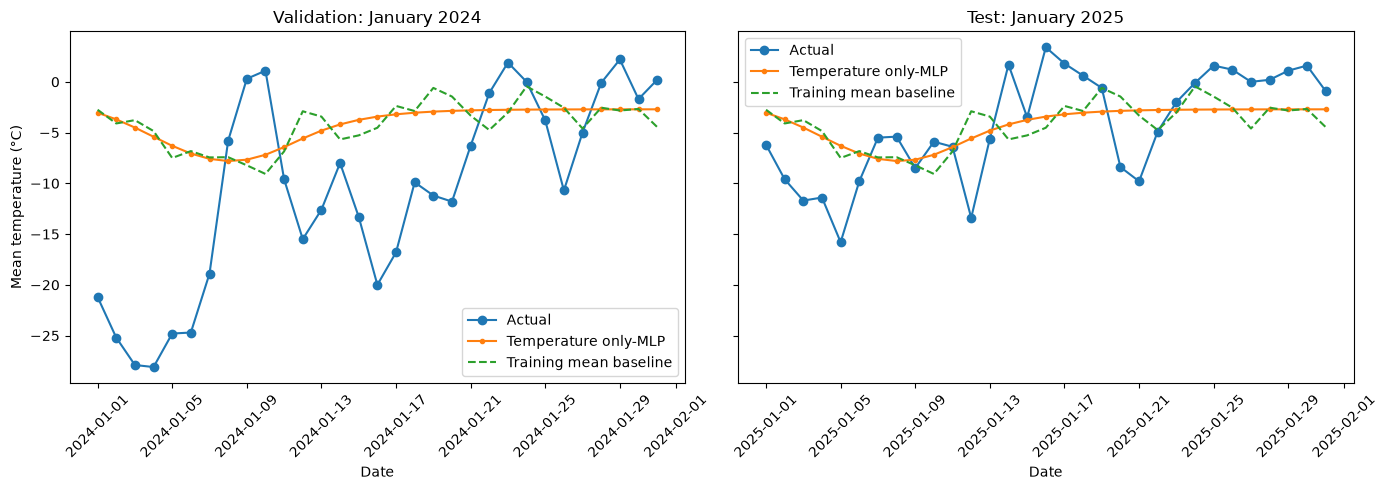

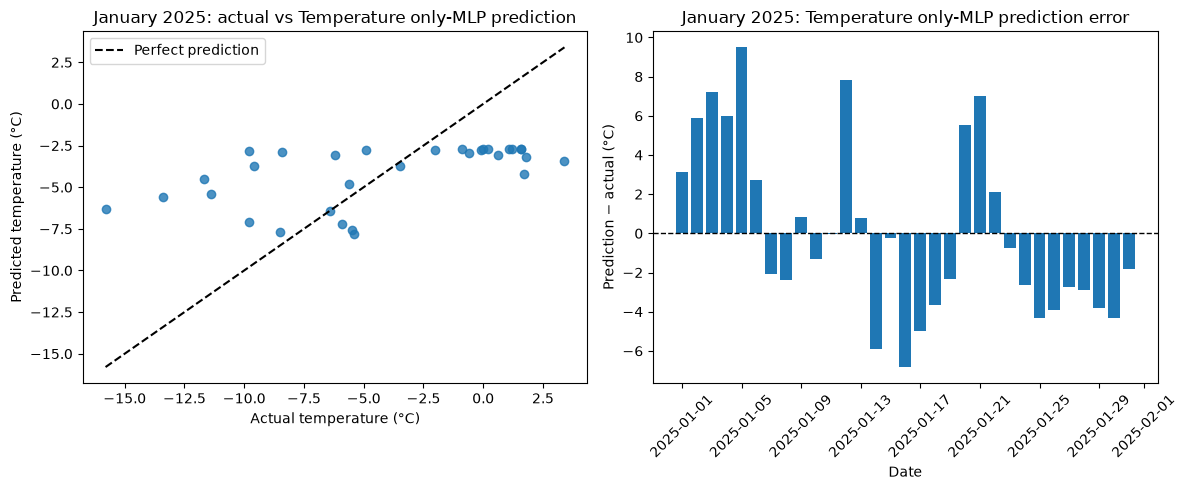

In [17]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].plot(validation["time"], y_validation, marker="o", label="Actual")
axes[0].plot(validation["time"], selected_model.predict(X_validation), marker=".", label="Temperature only-MLP")
axes[0].plot(validation["time"], validation_baseline, linestyle="--", label="Training mean baseline")
axes[0].set_title("Validation: January 2024")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Mean temperature (°C)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].plot(test["time"], y_test, marker="o", label="Actual")
axes[1].plot(test["time"], test_predictions, marker=".", label="Temperature only-MLP")
axes[1].plot(test["time"], test_baseline, linestyle="--", label="Training mean baseline")
axes[1].set_title("Test: January 2025")
axes[1].set_xlabel("Date")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_test, test_predictions, alpha=0.8)
low = min(float(y_test.min()), float(test_predictions.min()))
high = max(float(y_test.max()), float(test_predictions.max()))
axes[0].plot([low, high], [low, high], "k--", label="Perfect prediction")
axes[0].set_title("January 2025: actual vs Temperature only-MLP prediction")
axes[0].set_xlabel("Actual temperature (°C)")
axes[0].set_ylabel("Predicted temperature (°C)")
axes[0].legend()

axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].bar(test["time"], predictions["mlp_error_c"])
axes[1].set_title("January 2025: Temperature only-MLP prediction error")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Prediction − actual (°C)")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

## 6. Add humidity, windspeed, and pressure

This second MLP uses the same January 2020–2023 training dates, January 2024 validation dates, and January 2025 test dates as the Temperature only-MLP. Its inputs are day of month, relative humidity, windspeed, and pressure. We select among the same hidden-layer options using validation MAE, and fit scaling only on the training set.

Because the added weather measurements are observed on the date being evaluated, this experiment estimates temperature from same-day conditions; it is not a forecast that could be made before those conditions are measured.

In [11]:
WEATHER_FEATURES = ["day_of_month", "humidity_pct", "wind_speed_kmh", "pressure_hpa"]
X_weather_train = train[WEATHER_FEATURES]
X_weather_validation = validation[WEATHER_FEATURES]
X_weather_test = test[WEATHER_FEATURES]

weather_candidate_models = {}
weather_validation_rows = []
for hidden_sizes in HIDDEN_LAYER_OPTIONS:
    model = make_model(hidden_sizes)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        model.fit(X_weather_train, y_train)
    weather_candidate_models[hidden_sizes] = model
    weather_validation_rows.append({
        "hidden layers": str(hidden_sizes),
        **regression_metrics(y_validation, model.predict(X_weather_validation)),
    })

weather_validation_results = pd.DataFrame(weather_validation_rows).set_index("hidden layers")
weather_best_index = int(weather_validation_results["MAE (°C)"].to_numpy().argmin())
weather_selected_hidden_sizes = HIDDEN_LAYER_OPTIONS[weather_best_index]
weather_selected_model = weather_candidate_models[weather_selected_hidden_sizes]
print(f"Selected weather-informed hidden-layer sizes: {weather_selected_hidden_sizes}")
display(weather_validation_results.sort_values("MAE (°C)").round(3))

Selected weather-informed hidden-layer sizes: (4, 2)


,MAE (°C),RMSE (°C),R²
hidden layers,,,
"(4, 2)",5.584,6.974,0.457
"(4,)",5.986,7.739,0.331
"(8,)",6.826,8.780,0.139


## 7. Compare both models and their accuracy

Both models are scored on the exact same validation and held-out test dates. For regression, there is no classification-style accuracy percentage: lower MAE and RMSE and higher R² indicate better performance. The test table also reports how much the weather-informed model reduces MAE relative to the day-only model.

In [18]:
weather_test_predictions = weather_selected_model.predict(X_weather_test)
date_only_test_predictions = selected_model.predict(X_test)
weather_validation_predictions = weather_selected_model.predict(X_weather_validation)
date_only_validation_predictions = selected_model.predict(X_validation)

comparison_rows = []
for split_name, actual, date_only_pred, weather_pred in [
    ("Validation (January 2024)", y_validation, date_only_validation_predictions, weather_validation_predictions),
    ("Test (January 2025)", y_test, date_only_test_predictions, weather_test_predictions),
]:
    comparison_rows.extend([
        {"split": split_name, "model": "Temperature only-MLP", **regression_metrics(actual, date_only_pred)},
        {"split": split_name, "model": "Weather-informed MLP", **regression_metrics(actual, weather_pred)},
    ])

model_comparison = pd.DataFrame(comparison_rows).set_index(["split", "model"])
display(model_comparison.round(3))

date_only_test_mae = mean_absolute_error(y_test, date_only_test_predictions)
weather_test_mae = mean_absolute_error(y_test, weather_test_predictions)
mae_reduction_pct = 100 * (date_only_test_mae - weather_test_mae) / date_only_test_mae
print(f"January 2025 MAE change vs Temperature only-MLP: {mae_reduction_pct:+.1f}% (positive means lower error with weather inputs).")

MAE (°C)  RMSE (°C)     R²
split                     model                                           
Validation (January 2024) Temperature only-MLP     8.879     11.153 -0.389
                          Weather-informed MLP     5.584      6.974  0.457
Test (January 2025)       Temperature only-MLP     3.726      4.426  0.270
                          Weather-informed MLP     3.047      4.041  0.391

January 2025 MAE change vs Temperature only-MLP: +18.2% (positive means lower error with weather inputs).


## 8. Graph the predictions and model comparison

These charts are displayed inline in the notebook: January 2025 actual temperatures against both models' predictions, followed by MAE, RMSE, and R² comparisons for the validation and test periods.

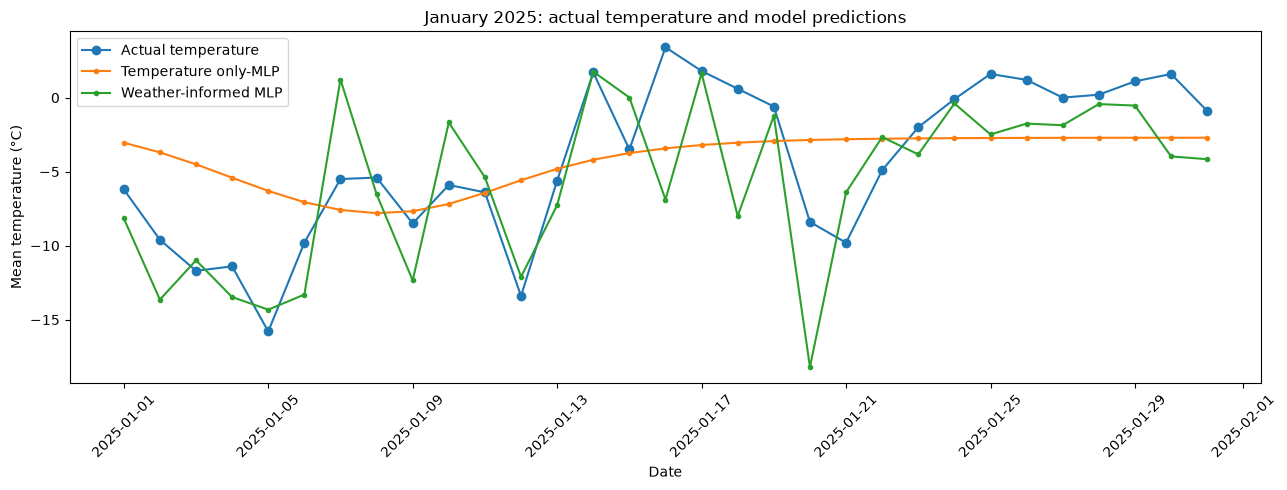

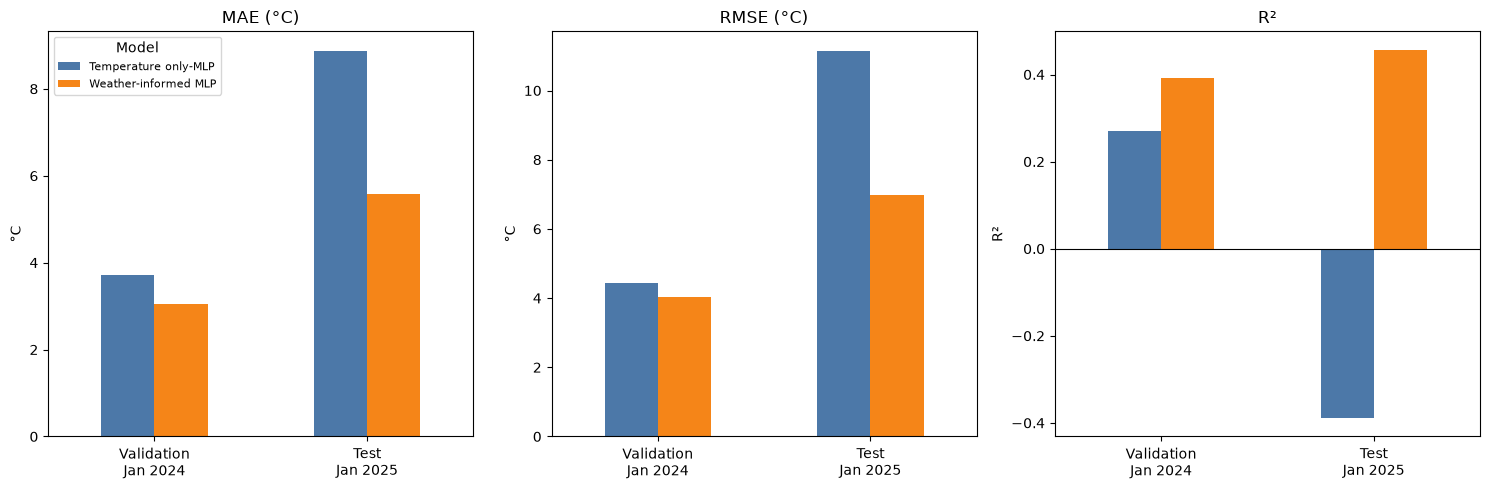

In [19]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test["time"], y_test, marker="o", label="Actual temperature")
ax.plot(test["time"], date_only_test_predictions, marker=".", label="Temperature only-MLP")
ax.plot(test["time"], weather_test_predictions, marker=".", label="Weather-informed MLP")
ax.set_title("January 2025: actual temperature and model predictions")
ax.set_xlabel("Date")
ax.set_ylabel("Mean temperature (°C)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
plt.show()

metrics_to_plot = ["MAE (°C)", "RMSE (°C)", "R²"]
fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(15, 5))
for ax, metric in zip(axes, metrics_to_plot):
    metric_by_split = model_comparison[metric].unstack("model")
    metric_by_split.index = ["Validation\nJan 2024", "Test\nJan 2025"]
    metric_by_split.plot(kind="bar", ax=ax, color=["#4C78A8", "#F58518"])
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("°C" if metric != "R²" else "R²")
    ax.tick_params(axis="x", rotation=0)
    if metric == "R²":
        ax.axhline(0, color="black", linewidth=0.8)
    if ax is not axes[0]:
        ax.get_legend().remove()
    else:
        ax.legend(title="Model", fontsize=8)
fig.tight_layout()
plt.show()

## Interpretation and limitations

- **MAE** is the average absolute error in °C; **RMSE** penalizes larger errors more; **R²** compares against predicting the test-set mean and can be negative.
- Compare the test metrics for the Temperature only-MLP and weather-informed MLP, and check whether either improves on the day-of-month training-mean baseline. A more complex model is not automatically better, especially with just 124 training observations.
- The weather-informed MLP uses humidity, windspeed, and pressure recorded on each January 2025 date. These same-day inputs are useful for comparing relationships, but are unavailable before the date; this is not an operational forecast.
- For fair comparisons with other models, keep these exact year splits, inputs, and metrics fixed. A future forecasting experiment should use only information available at the time of prediction, such as clearly defined lagged measurements.